# Notebook 7 · Question 8: uncertainty, fairness, recommendation and reproducibility
Runs `src/fairness_q8.py` (bootstrap intervals, calibration, performance by province and type on the test year) and `src/experiment_log.py`.

In [1]:
import sys, json, logging, warnings
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
logging.disable(logging.WARNING)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", "{:.3f}".format)
RESULTS, FIGS = ROOT / "results", ROOT / "reports" / "figures"
show = lambda name, width=800: display(Image(filename=str(FIGS / name), width=width))

In [2]:
import fairness_q8, experiment_log
fairness_q8.main()
experiment_log.main()

95% bootstrap CIs on the test year:
  accuracy           0.908  [0.871, 0.942]
  macro_f1           0.906  [0.866, 0.941]
  recall_at_risk     0.874  [0.802, 0.934]
  precision_at_risk  0.909  [0.851, 0.963]
  roc_auc            0.896  [0.845, 0.940]
Brier score 0.088; status changes in test year: 22 (accuracy on them 0%, on stable municipalities 100%)



By province:
     province  n  actual_at_risk  actual_share  flagged_share  accuracy  recall_at_risk  false_positive_rate  reliable
KwaZulu-Natal 54              11         0.204          0.204     0.926           0.818                0.047      True
 Eastern Cape 38              18         0.474          0.421     0.895           0.833                0.050      True
 Western Cape 28               3         0.107          0.107     0.929           0.667                0.040     False
Northern Cape 27              20         0.741          0.704     0.815           0.850                0.286      True
      Limpopo 26              10         0.385          0.308     0.846           0.700                0.062      True
   Mpumalanga 20              10         0.500          0.550     0.950           1.000                0.100      True
   Free State 19              13         0.684          0.684     1.000           1.000                0.000     False
   North West 17              15  


Saved results/q8_*.csv/json and reports/figures/q8_fairness.png, q8_calibration.png


Wrote C:\Users\tshin\OneDrive\Desktop\TUT\IDA\IDAproject-Tshinavhe\docs\experiment_log.md


## Uncertainty and calibration

,estimate,ci95_low,ci95_high
accuracy,0.908,0.871,0.942
macro_f1,0.906,0.866,0.941
recall_at_risk,0.874,0.802,0.934
precision_at_risk,0.909,0.851,0.963
roc_auc,0.896,0.845,0.940


Brier score: 0.088
Status changes in the test year: 22 (accuracy on them 0%, on stable municipalities 100%)
2025 forecast: {'n': 245, 'flagged': 106, 'close_calls_40_60': 0, 'forecast_status_changes': 0, 'expected_status_changes_at_test_rate': 22.458333333333332}


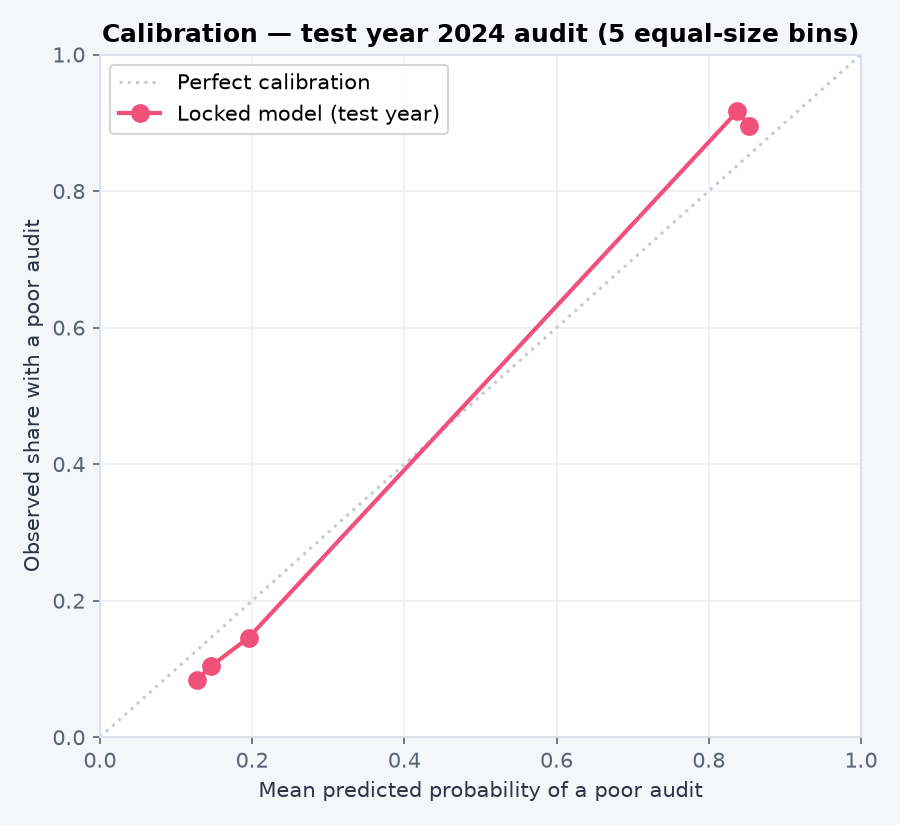

In [3]:
q8 = json.loads((RESULTS / "q8_uncertainty.json").read_text())
display(pd.DataFrame(q8["metrics_ci95"]).T)
print("Brier score:", round(q8["brier_score"], 3))
print(f"Status changes in the test year: {q8['status_changes_in_test']} (accuracy on them {q8['accuracy_on_status_changes']:.0%}, "
      f"on stable municipalities {q8['accuracy_on_stable']:.0%})")
print("2025 forecast:", q8["forecast_2025"])
show("q8_calibration.png", 420)

## Fairness by province and municipality type

,province,n,actual_at_risk,actual_share,flagged_share,accuracy,recall_at_risk,false_positive_rate,reliable
0,KwaZulu-Natal,54,11,0.204,0.204,0.926,0.818,0.047,True
1,Eastern Cape,38,18,0.474,0.421,0.895,0.833,0.050,True
2,Western Cape,28,3,0.107,0.107,0.929,0.667,0.040,False
3,Northern Cape,27,20,0.741,0.704,0.815,0.850,0.286,True
4,Limpopo,26,10,0.385,0.308,0.846,0.700,0.062,True
5,Mpumalanga,20,10,0.500,0.550,0.950,1.000,0.100,True
6,Free State,19,13,0.684,0.684,1.000,1.000,0.000,False
7,North West,17,15,0.882,0.824,0.941,0.933,0.000,False
8,Gauteng,11,3,0.273,0.364,0.909,1.000,0.125,False


,category,n,actual_at_risk,actual_share,flagged_share,accuracy,recall_at_risk,false_positive_rate,reliable
0,Local,190,88,0.463,0.447,0.889,0.864,0.088,True
1,District,42,11,0.262,0.262,1.000,1.000,0.000,True
2,Metro,8,4,0.500,0.375,0.875,0.750,0.000,False


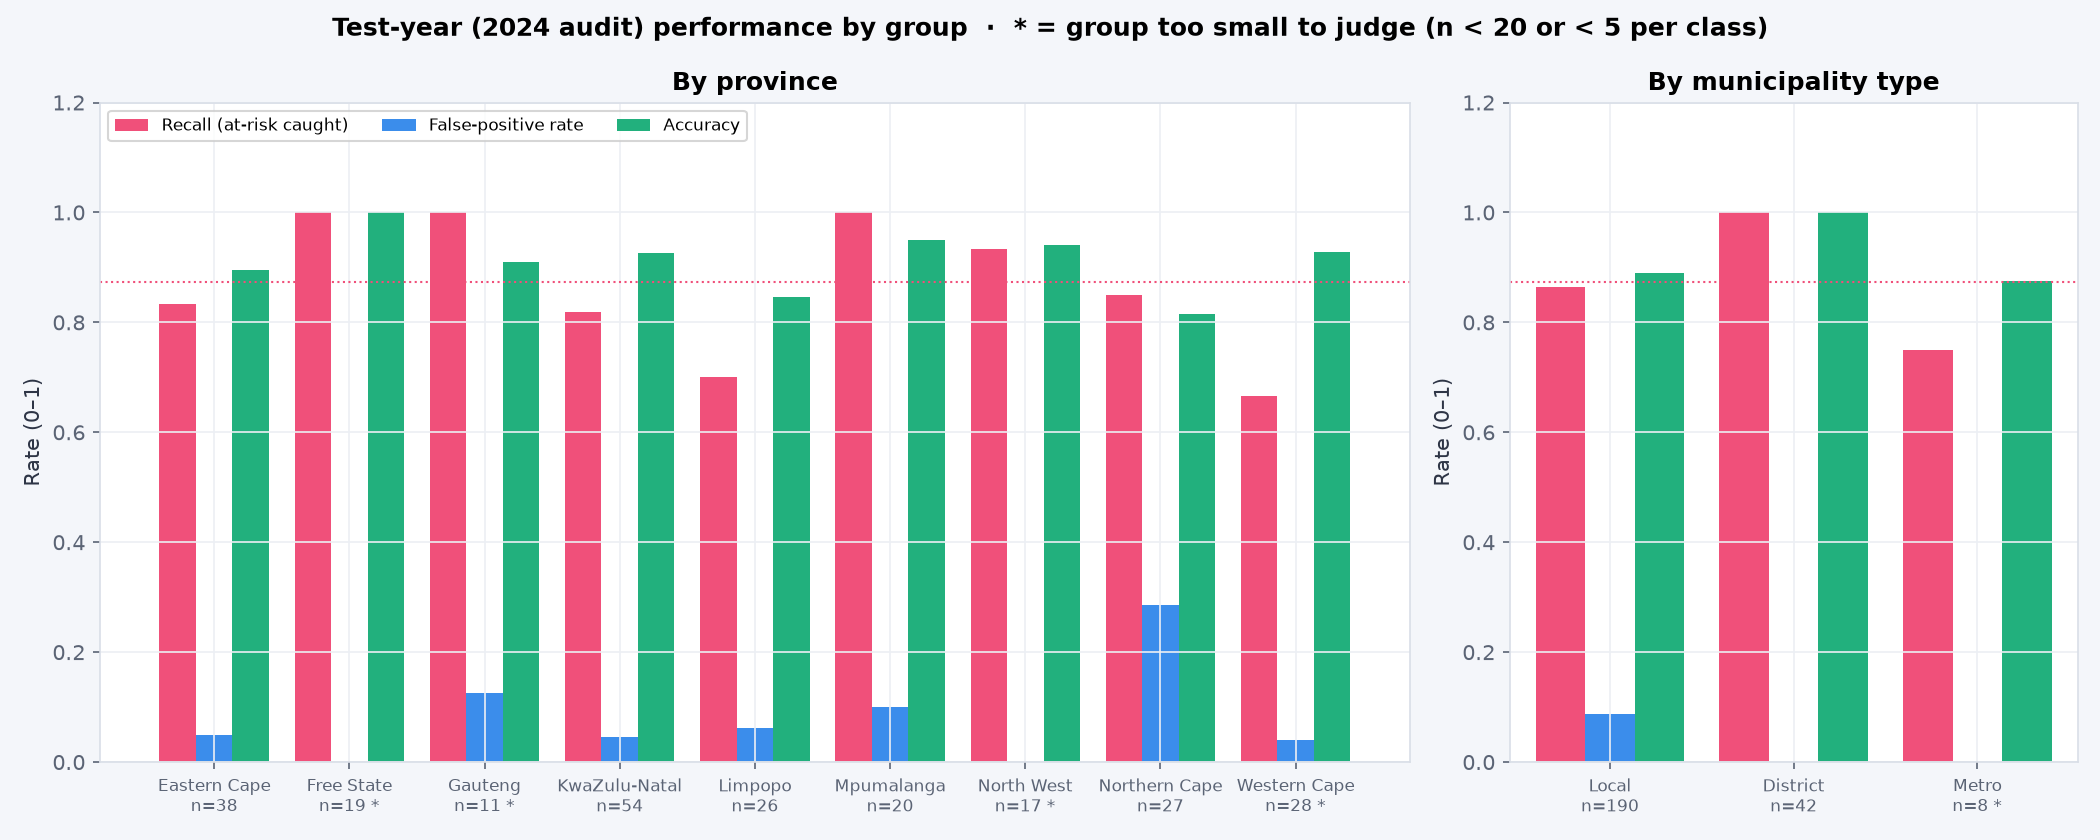

In [4]:
display(pd.read_csv(RESULTS / "q8_fairness_province.csv"))
display(pd.read_csv(RESULTS / "q8_fairness_type.csv"))
show("q8_fairness.png", 900)

## 8.1 Recommendation
Use the model as a **consistent, explainable triage list for municipalities already in difficulty**, not as an early-warning system:
its decisions equal "repeat last year's outcome", it misclassifies every municipality whose status changes, and false alarms are uneven
across provinces (review flagged lists by province). Monitor yearly against the published AGSA outcomes and retrain if macro-F1 falls
below the lower confidence bound. Never use it to allocate funding automatically or to penalise municipalities.
## 8.2 Reproducibility
`python run_all.py` reproduces every result (seed 42, pinned `requirements.txt`); the experiment log is regenerated below.

In [5]:
print((ROOT / "docs" / "experiment_log.md").read_text()[:3000])

# Experiment log

Generated by `src/experiment_log.py` on 2026-10-20 from the files in `results/`. Random seed 42 everywhere. Split: train = feature years 2018â€“2021 (950 rows), validation = 2022 (244), test = 2023 (240, used once in Q5.3). Target = AGSA outcome in year t+1 (at_risk vs not_at_risk).

## 1. Model configurations (Q3)

- **Baseline (Dummy):** `DummyClassifier` strategy=most_frequent
- **Baseline (Repeat last year):** `PriorOutcomeRule` 
- **Logistic Regression:** `LogisticRegression` C=1.0, class_weight=balanced, dual=False, fit_intercept=True, intercept_scaling=1, l1_ratio=0.0, max_iter=2000, random_state=42, solver=lbfgs, tol=0.0001
- **Random Forest:** `RandomForestClassifier` bootstrap=True, ccp_alpha=0.0, class_weight=balanced, criterion=gini, max_features=sqrt, min_impurity_decrease=0.0, min_samples_leaf=1, min_samples_split=2, min_weight_fraction_leaf=0.0, n_estimators=200, oob_score=False, random_state=42
- **MLP:** `TorchTabularClassifier` arch=mlp, batch_size=3